In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import numpy as  np
import seaborn as sns

In [2]:
import dashboard as ds
importlib.reload(ds)

<module 'dashboard' from 'd:\\Universidad\\TPE - Ciencia de datos\\dashboard.py'>

In [3]:
import utils
importlib.reload(utils)

<module 'utils' from 'd:\\Universidad\\TPE - Ciencia de datos\\utils.py'>

In [375]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Distribucion de variables

In [5]:
def maping_and_add(col, values_change, min, dash, multiple=False):
    if not multiple:
        values = df[col].value_counts().index.to_list()
    else:
        values = (
            df[col]
            .dropna()
            .str.split(';')
            .explode()
            .str.strip()
            .value_counts()
        ).index.to_list()
    mapeo = {}
    for i, val in enumerate(values):
        if i == len(values_change): break
        mapeo[val] = values_change[i]
    dash.add.bar(df, col, min=min, cut=mapeo, multiple_r=multiple, max_cat=len(values_change))

<h4><u>Demografía y Perfil Laboral

In [6]:
def histEs(bins=5):
    def draw(ax):
        comp = df['CompTotal'].dropna()
        limite = comp.quantile(0.85)

        comp[comp <= limite].hist(
            bins=bins,
            edgecolor='black',
            ax=ax
        )

        ax.set_title('CompTotal:85%')
        ax.set_xlabel('')
        ax.grid(False)
        ax.tick_params(axis="x", rotation=45)

    return ds.Chart(draw=draw)

In [94]:
dash1 = ds.Dashboard(columns=4, figsize=(20, 4))

In [95]:
maping_and_add('MainBranch', [1, 2, 3, 4, 5, 6], min=2000, dash=dash1)
maping_and_add('EdLevel', ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps'], min=2000, dash=dash1)
maping_and_add('OrgSize', ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK'], min=2400, dash=dash1)
maping_and_add('DevType', ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e'], min=2400, dash=dash1)
maping_and_add('RemoteWork', ['Remote', 'H_p', 'Person', 'H_r', 'Choice'], min=2400, dash=dash1)
maping_and_add('NewRole', ['No', 'con_1', 'con_2', 'Yes_v', 'Yes_i'], min=2400, dash=dash1)

In [96]:
#this
df['Employment'] = df['Employment'].replace('Independent contractor, freelancer, or self-employed', 'Independent')
dash1.add.bar(df, "Employment", min=1000, cut=6)

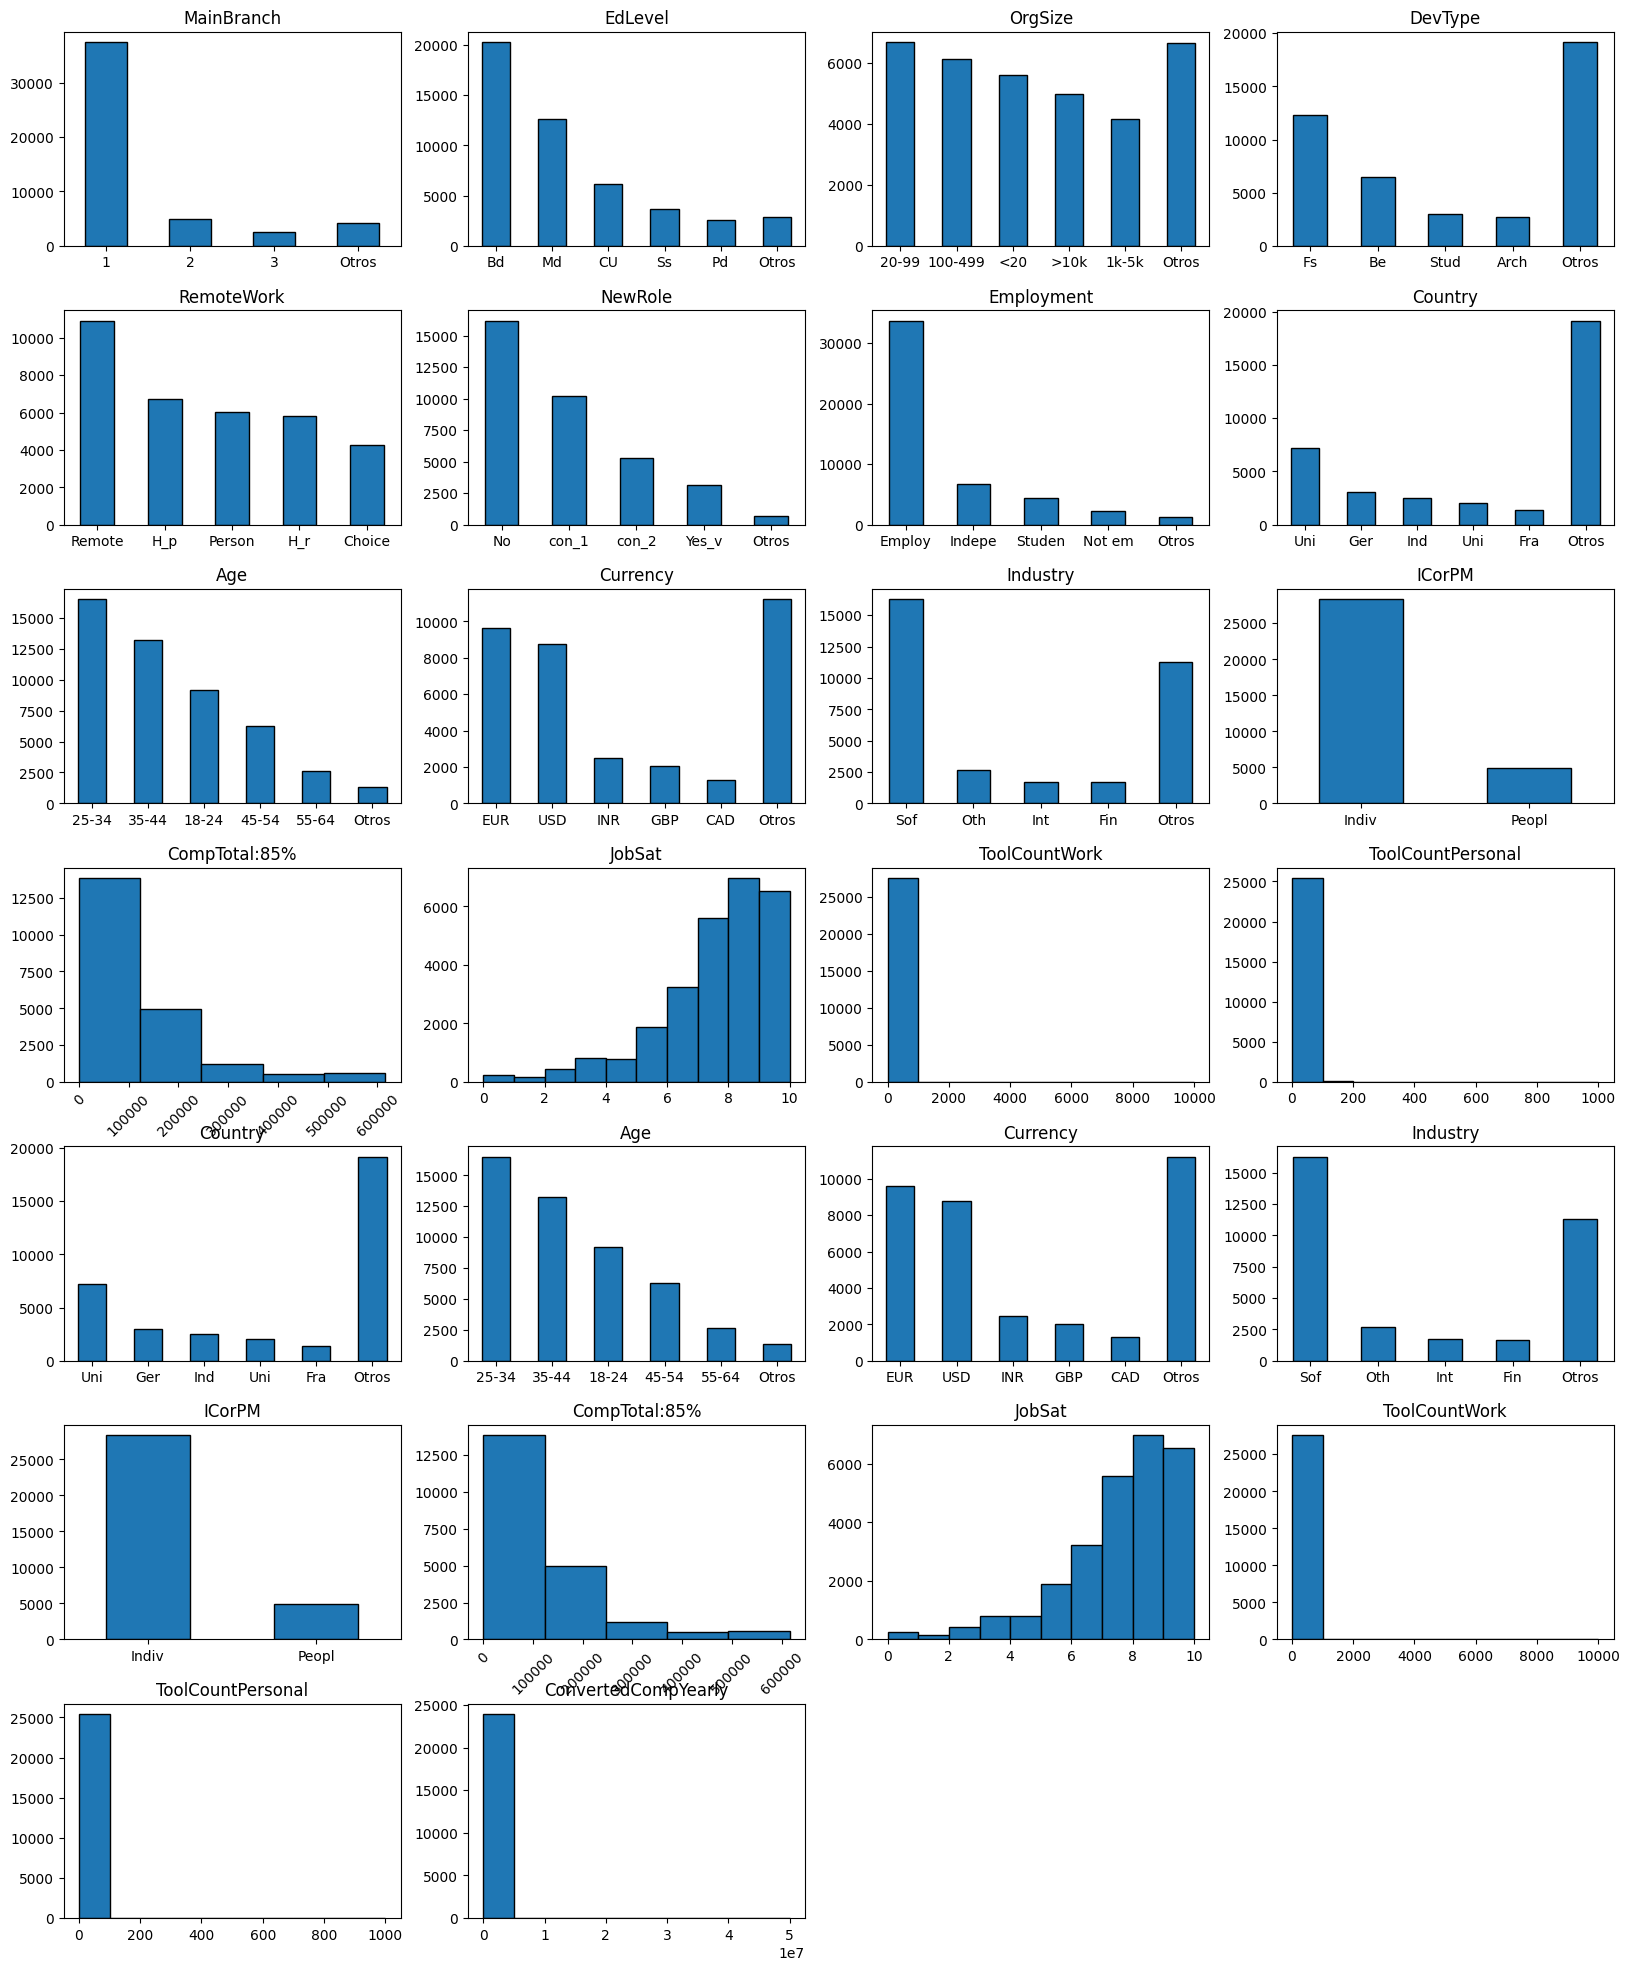

In [98]:
dash1.add.bar(df, "Country", min=1000, cut=3)
dash1.add.bar(df, "Age", min=2000, cut=' ')
dash1.add.bar(df, "Currency", min=1000, cut=3)
dash1.add.bar(df, "Industry", min=1500, cut=3)
dash1.add.bar(df, "ICorPM", min=1500, cut=5)
dash1.addChart(histEs(bins=5))
columnas1 = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole',
    'ToolCountWork',
    'ToolCountPersonal',
    'ConvertedCompYearly'
]
dash1.add.multiple_hist(df, columnas1, bins=10)

dash1.show()

<h4><u>Experencia y aprendizaje

In [11]:
dash2 = ds.Dashboard(columns=4, figsize=(20, 4))

In [12]:
columnas2 = [
    'WorkExp',
    'YearsCode',
    'LearnCodeChoose',
    'LearnCode',
    'LearnCodeAI',
    'AILearnHow',
]
dash2.add.multiple_hist(df, columnas2, bins=12)
maping_and_add('LearnCodeChoose', ['yes - master', 'no - master', 'yes = junr'], 0, dash2)
#maping_and_add('LearnCode', [], 0, dash2)
maping_and_add('LearnCodeAI', ['IA_Prof', 'IA_Pers', 'NoIA_Pers', 'No_learn', 'NoIA_Prof'], 0, dash2)
#maping_and_add('AILearnHow', [], 0, dash2)

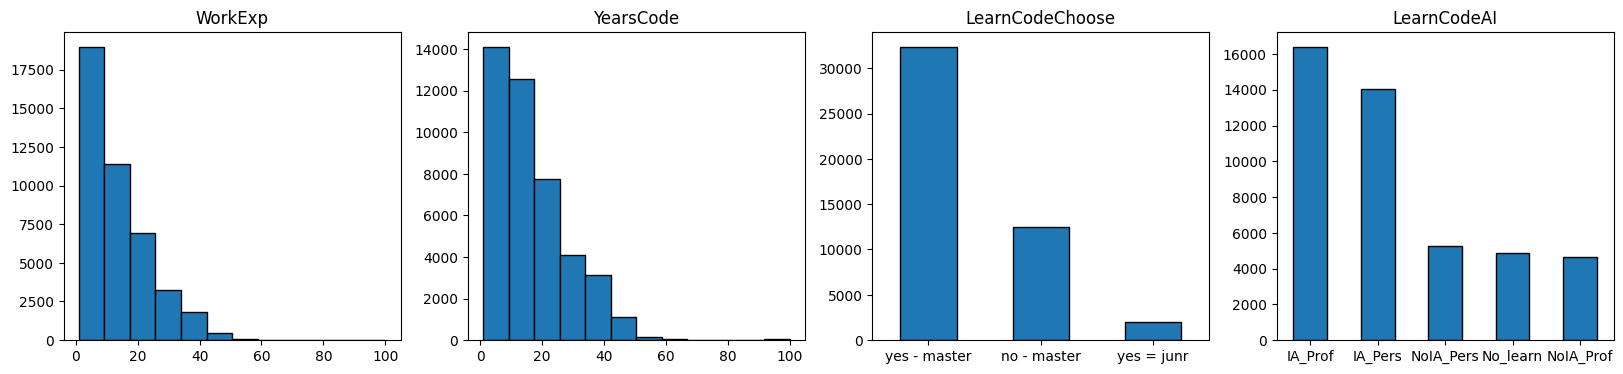

In [13]:
dash2.show()

<h4><u>Stack Tecnológico y Herramientas

In [14]:
dash3 = ds.Dashboard(columns=4, figsize=(20, 4))

In [15]:
def all_columns(df, start, values_change=[], min=0, ignored=None):
    sub = df.loc[:, df.columns.str.startswith(start)]
    for i in sub:
        if i != start + 'Choice' and (not ignored or i != start + ignored):
            maping_and_add(i, values_change, min, dash3, multiple=True)

In [16]:
columnas3 = [
    'LanguageChoice',
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LanguageAdmired',
    'DatabaseChoice',
    'DatabaseHaveWorkedWith',
    'DatabaseWantToWorkWith',
    'DatabaseAdmired',
    'PlatformChoice',
    'PlatformHaveWorkedWith',
    'PlatformWantToWorkWith',
    'PlatformAdmired',
    'WebframeChoice',
    'WebframeHaveWorkedWith',
    'WebframeWantToWorkWith',
    'WebframeAdmired',
    'DevEnvsChoice',
    'DevEnvsHaveWorkedWith',
    'DevEnvsWantToWorkWith',
    'DevEnvsAdmired',
    'OpSysPersonal use',
    'OpSysProfessional use',
    'OfficeStackAsyncHaveWorkedWith',
    'OfficeStackAsyncWantToWorkWith',
    'OfficeStackAsyncAdmired',
    'CommPlatformHaveWorkedWith',
    'CommPlatformWantToWorkWith',
    'CommPlatformAdmired',
    'AIModelsChoice',
    'AIModelsHaveWorkedWith',
    'AIModelsWantToWorkWith',
    'AIModelsAdmired',
]

In [17]:
dash3.add.bar(df, 'LanguageChoice', 0)
all_columns(df, 'Language', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 10000, 'Admired')
maping_and_add('LanguageAdmired', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 5000, dash3, multiple=True)

In [18]:
dash3.add.bar(df, 'DatabaseChoice', 0)
maping_and_add('DatabaseHaveWorkedWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 7000, dash3, multiple=True)
maping_and_add('DatabaseWantToWorkWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)
maping_and_add('DatabaseAdmired', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)

In [19]:
dash3.add.bar(df, 'PlatformChoice', 0)
maping_and_add('PlatformHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 6900, dash3, multiple=True)
maping_and_add('PlatformWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('PlatformAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)

In [20]:
dash3.add.bar(df, 'WebframeChoice', 0)
maping_and_add('WebframeHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 1000, dash3, multiple=True)

In [21]:
dash3.add.bar(df, 'DevEnvsChoice', 0)
maping_and_add('DevEnvsHaveWorkedWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsWantToWorkWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsAdmired', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 1000, dash3, multiple=True)

In [22]:
maping_and_add('OfficeStackAsyncHaveWorkedWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncWantToWorkWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncAdmired', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 1000, dash3, multiple=True)

In [23]:
maping_and_add('CommPlatformHaveWorkedWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformWantToWorkWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformAdmired', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 1000, dash3, multiple=True)

In [24]:
dash3.add.bar(df, 'AIModelsChoice', 0)
maping_and_add('AIModelsHaveWorkedWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsWantToWorkWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsAdmired', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 1000, dash3, multiple=True)

In [25]:
del dash3.charts[-4:]

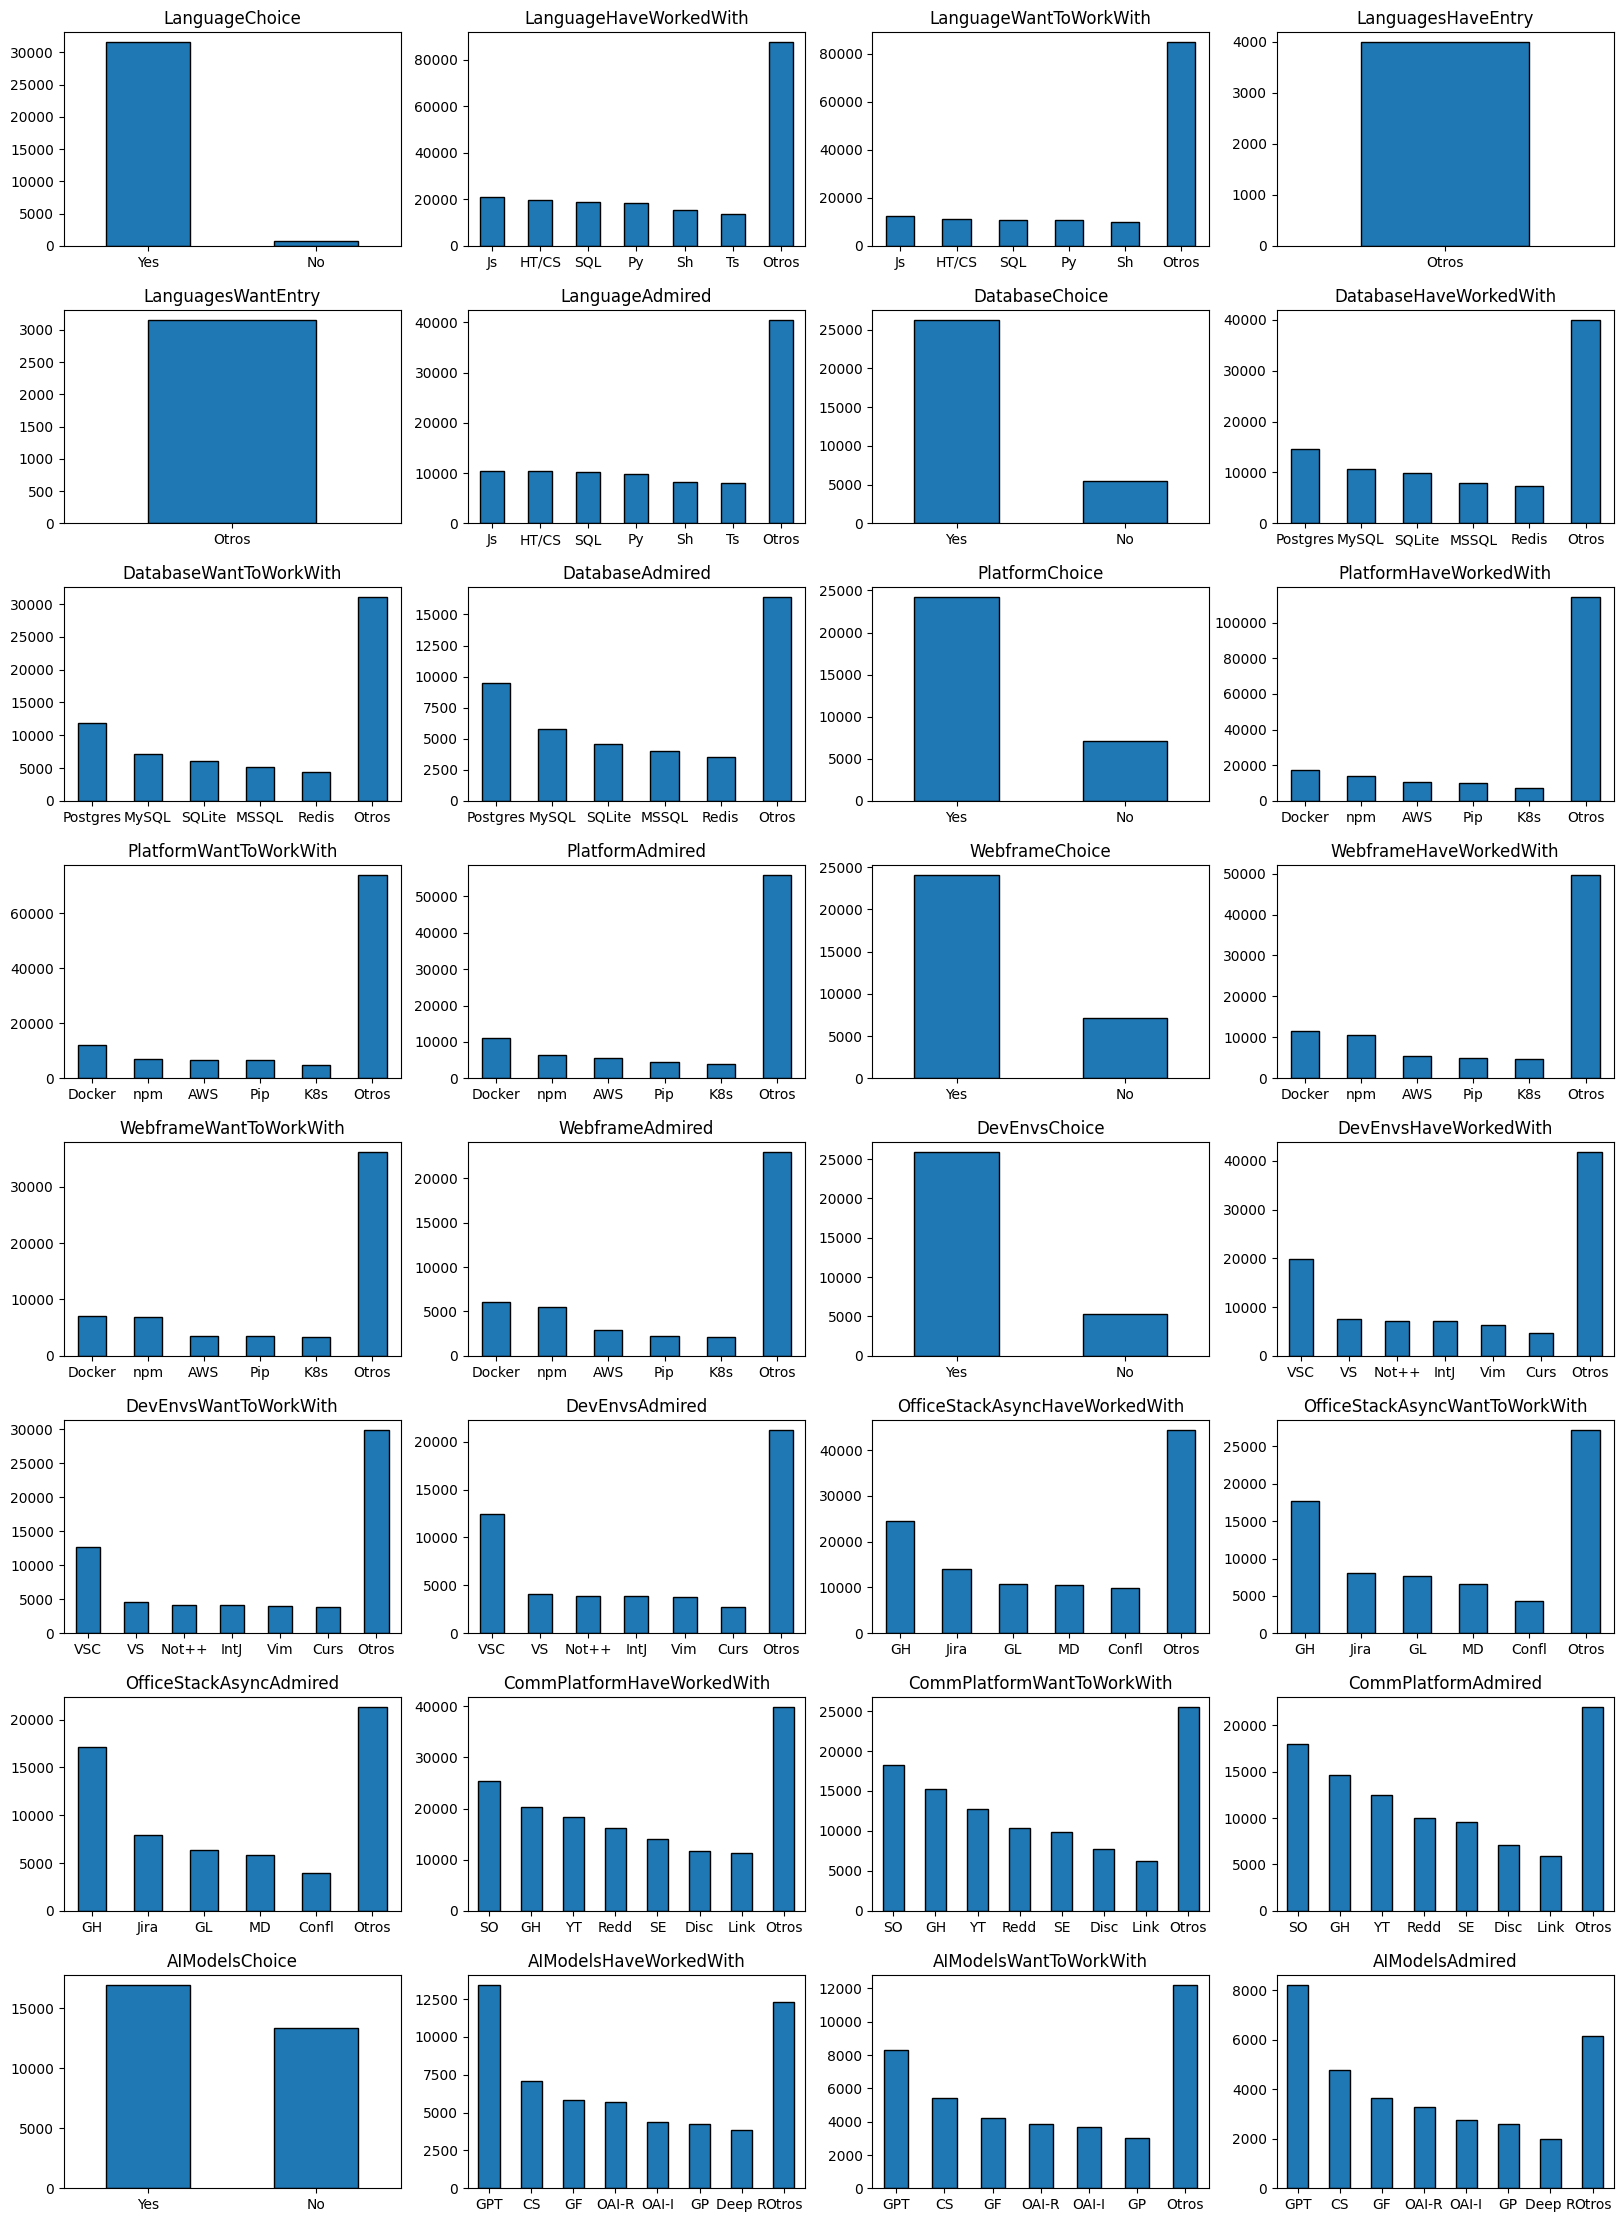

In [25]:
dash3.show()

<h3 style="color: violet;">Matriz de correlacion

Durante el analisis solo encontramos una relacion fuerte por encima del 0.6, tratandose del par (WorkExpr, YearsCode) teniendo sentido porque la gran mayoria de desarrolladores crecen en ambos ejes a lo largo del tiempo.

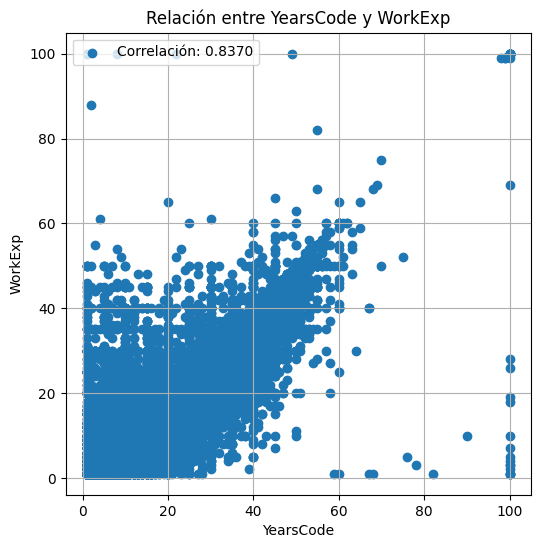

In [100]:
import re
correlation_matrix = df.corr(numeric_only=True)
corr_whithout_diag = correlation_matrix.mask(np.eye(len(correlation_matrix), dtype=bool))
cols = corr_whithout_diag.columns[corr_whithout_diag.abs().gt(0.6).any()]
correlation_matrix = correlation_matrix.loc[cols, cols]
correlation_matrix

,WorkExp,YearsCode
WorkExp,1.000000,0.837283
YearsCode,0.837283,1.000000


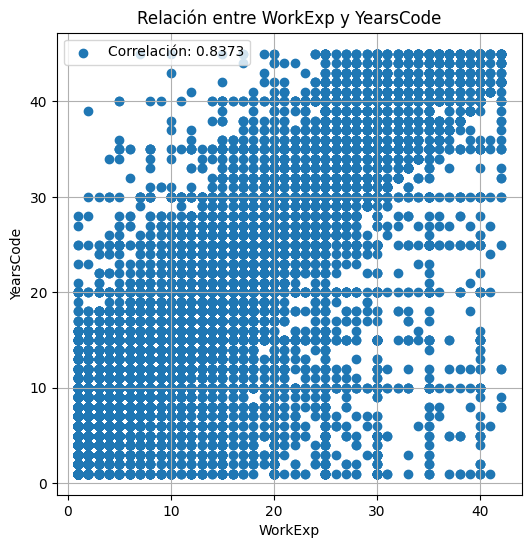

In [107]:
utils.scatter('WorkExp', 'YearsCode', df, alpha=1)

<h3 style="color: violet;">Reduccion de dimensionalidad

In [ ]:
cols_mc = [
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LanguageAdmired',
    'EmploymentAddl',
    'AILearnHow',
    'DatabaseHaveWorkedWith',
    'DatabaseWantToWorkWith',
    'DatabaseAdmired',
    'PlatformHaveWorkedWith',
    'PlatformWantToWorkWith',
    'PlatformAdmired',
    'WebframeHaveWorkedWith',
    'WebframeWantToWorkWith',
    'WebframeAdmired',
    'DevEnvsHaveWorkedWith',
    'DevEnvsWantToWorkWith',
    'DevEnvsAdmired',
    'SOTagsHaveWorkedWith',
    'SOTagsWantToWorkWith',
    'SOTagsAdmired',
    'OpSysPersonal use',
    'OpSysProfessional use',
    'OfficeStackAsyncHaveWorkedWith',
    'OfficeStackAsyncWantToWorkWith',
    'OfficeStackAsyncAdmired',
    'CommPlatformHaveWorkedWith',
    'CommPlatformWantToWorkWith',
    'CommPlatformAdmired',
    'AIModelsHaveWorkedWith',
    'AIModelsWantToWorkWith',
    'AIModelsAdmired',
    'AIToolCurrently partially AI',
    "AIToolDon't plan to use AI for this task",
    'AIToolPlan to partially use AI',
    'AIToolPlan to mostly use AI',
    'AIToolCurrently mostly AI',
    'AIAgent_Uses',
    'AgentUsesGeneral',
    'AIAgentImpactSomewhat agree',
    'AIAgentImpactNeutral',
    'AIAgentImpactSomewhat disagree',
    'AIAgentImpactStrongly agree',
    'AIAgentImpactStrongly disagree',
    'AIAgentChallengesNeutral',
    'AIAgentChallengesSomewhat disagree',
    'AIAgentChallengesStrongly agree',
    'AIAgentChallengesSomewhat agree',
    'AIAgentChallengesStrongly disagree',
    'AIAgentKnowledge',
    'AIAgentOrchestration',
    'AIAgentOrchWrite', #con coma
    'AIAgentObserveSecure',
    'AIAgentObsWrite',
    'AIAgentExternal',
    'AIAgentExtWrite', #con coma
    'AIHuman'
]

cols_yes_no = [
    'LanguageChoice',
    'DatabaseChoice',
    'PlatformChoice',
    'WebframeChoice',
    'DevEnvsChoice',
    'AIModelsChoice',
]

In [387]:
var_objetivo = 'AIThreat'

In [388]:
mapa_confianza = {
    'Very poor at handling complex tasks': 1,
    'Bad at handling complex tasks': 2,
    'Neither good or bad at handling complex tasks': 3,
    'Good, but not great at handling complex tasks': 4,
    'Very well at handling complex tasks': 5,
    "I don't use AI tools for complex tasks / I don't know": np.nan
}

df['AIComplex'] = df['AIComplex'].map(mapa_confianza)

In [389]:
mapa_confianza = {
    'Highly distrust': 1,
    'Somewhat distrust': 2,
    'Neither trust nor distrust': 3,
    'Somewhat trust': 4,
    'Highly trust': 5,
}

df['AIAcc'] = df['AIAcc'].map(mapa_confianza)

In [390]:

mapa_confianza = {
    'I have neither consider or transitioned into a new career or industry': 0,
    'I have somewhat considered changing my career and/or the industry I work in': 1,
    'I have strongly considered changing my career and/or the industry I work in': 1,
    'I have transitioned into a new career and/or industry voluntarily': 1,
    'I have transitioned into a new career and/or industry involuntarily': np.nan
}

df['NewRole'] = df['NewRole'].map(mapa_confianza)

In [391]:
# Transformación y limpieza: AIFrustration ✅

import numpy as np
import pandas as pd

# 1. Definimos el diccionario mapeando cada opción a su puntaje
mapeo_frustracion = {
    'AI solutions that are almost right, but not quite': 1,
    'Debugging AI-generated code is more time-consuming': 1,
    "I've become less confident in my own problem-solving": 1,
    "It's hard to understand how or why the code works": 1,
    "I haven't encountered any problems": 0,
    "I don't use AI tools regularly": 0
}                                                

# 2. Función para mapear y sumar cuando hay múltiples respuestas en una celda
def mapear_opciones_multiples(celda):
    if pd.isna(celda):
        return np.nan
    
    # Estandarizamos comillas (convierte comilla curvada ’ en estándar ')
    celda_normalizada = str(celda).replace('’', "'")
    
    # Separamos la celda por punto y coma
    opciones_seleccionadas = celda_normalizada.split(';')
    
    # Las entradas de "(write in)" generan datos ruidosos y dificiles de estandarizar por lo que buscamos cada opción en el diccionario (si no existe o es "Other", devuelve 0).
    score = sum(mapeo_frustracion.get(opcion.strip(), 0) for opcion in opciones_seleccionadas)
    
    return score

# 3. Aplicamos la transformación
df['AIFrustration_score'] = df['AIFrustration'].apply(mapear_opciones_multiples)

# 4. Verificamos los resultados
print(df['AIFrustration_score'].value_counts(dropna=False).sort_index())

# JobSat tiene ≈ 6.84% de nulos cuando se hace el tratamiento de las 4 variables anteriores. Decido eliminar esas filas ya que conservo más de 17500 registros, que sigue siendo un buen número a analizar.
df = df.dropna(subset=['AIFrustration_score'])

AIFrustration_score
0.0     4367
1.0     9454
2.0     8092
3.0     3136
4.0      815
NaN    16980
Name: count, dtype: int64


In [392]:
mapped = {
    '18-24 years old': 0,
    '25-34 years old': 1,
    '35-44 years old': 2,
    '45-54 years old': 3,
    '55-64 years old': 4,
    '65 years or older': 5,
    'Prefer not to say': np.nan
}

df['Age'] = df['Age'].map(mapped)

In [393]:
edlevel_map = {
    'Primary/elementary school': 0,
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 1,
    'Some college/university study without earning a degree': 2,
    'Associate degree (A.A., A.S., etc.)': 3,
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 4,
    "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": 5,
    'Professional degree (JD, MD, Ph.D, Ed.D, etc.)': 6,
    'Other (please specify):': np.nan
}

df['EdLevel'] = df['EdLevel'].map(edlevel_map)

In [394]:
orgsize_map = {
    'Just me - I am a freelancer, sole proprietor, etc.': 0,
    'Less than 20 employees': 1,
    '20 to 99 employees': 2,
    '100 to 499 employees': 3,
    '500 to 999 employees': 4,
    '1,000 to 4,999 employees': 5,
    '5,000 to 9,999 employees': 6,
    '10,000 or more employees': 7,
    "I don’t know": np.nan
}
df['OrgSize'] = df['OrgSize'].map(orgsize_map)

In [395]:
mapped = {
    'No': 0,
    'Yes': 1,
    "I'm not sure": np.nan
}
df['AIThreat'] = df['AIThreat'].map(mapped)

In [496]:
var_objetivo = 'AIAcc'

In [497]:
cols = ['WorkExp', 'ConvertedCompYearly', 'JobSat', 'YearsCode', 'AIThreat', 'Age', 'EdLevel', 'OrgSize', 'AIFrustration_score', 'AIAcc', 'AIComplex']
features = df[cols].drop(columns=[f'{var_objetivo}']).columns.to_list()
X_num = df[cols].dropna()

In [498]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_num.drop(columns=[f'{var_objetivo}']))

In [398]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP

In [438]:
pca = PCA(n_components=2, whiten=False)
tsne = TSNE(n_components=2, random_state=10)
umap = UMAP(n_components=2)

In [505]:
principalComponents_pca = pca.fit_transform(df_scaled)

In [502]:
principalComponents_tsne = tsne.fit_transform(df_scaled)

In [499]:
principalComponents_umap = umap.fit_transform(df_scaled)

In [506]:
principalComponents = principalComponents_pca

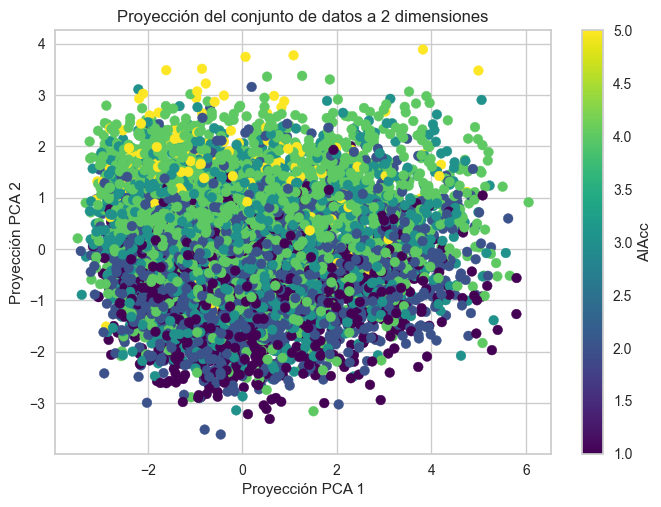

In [507]:
plt.scatter(principalComponents[:,0], principalComponents[:,1],c=X_num[f'{var_objetivo}'], cmap='viridis', alpha=1)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar(label=f'{var_objetivo}')
plt.show()

In [492]:
pca.explained_variance_ratio_

array([0.29465914, 0.17390425])

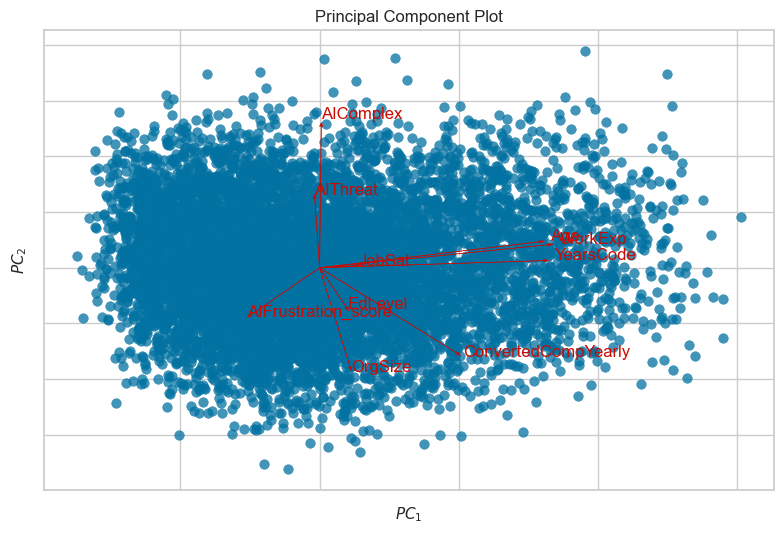

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [508]:
from calendar import c
from turtle import color

from narwhals import col
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=False,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
    features=features
)
# lo aplicamos sobre los datos originales
#df_viz = df.select_dtypes(include="number")
viz.fit_transform(df_scaled)
# y pedimos que se grafique
viz.show()

In [509]:
loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=features,
    columns=["PC1", "PC2"]
)
loadings.sort_values("PC1", ascending=False)

,PC1,PC2
WorkExp,0.542800,0.106313
YearsCode,0.531988,0.032856
Age,0.521984,0.119773
ConvertedCompYearly,0.325622,-0.393730
JobSat,0.088734,0.009103
OrgSize,0.072354,-0.457328
EdLevel,0.063794,-0.182750
AIComplex,0.003988,0.652541
AIThreat,-0.011408,0.319915
AIFrustration_score,-0.162898,-0.217864


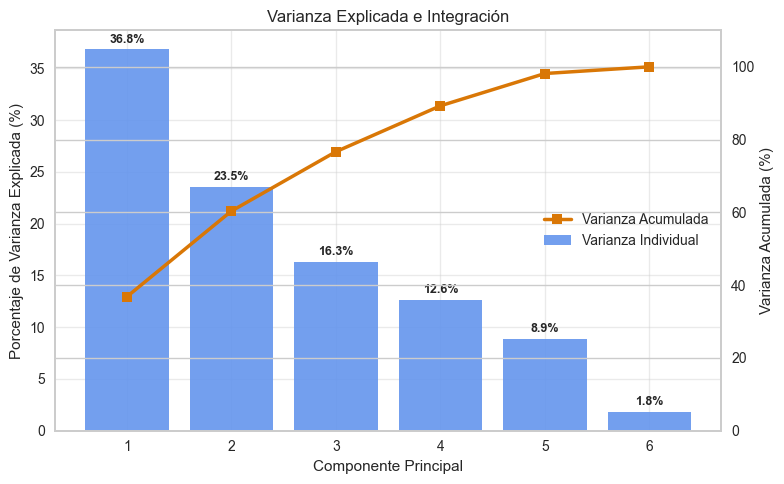

In [123]:
# Ajustar PCA con todas las componentes
pca = PCA()
pca.fit_transform(df_scaled)

# Calcular porcentajes
varianza_individual = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_individual)

componentes = np.arange(1, len(varianza_individual) + 1)

# Crear gráfico
fig, ax1 = plt.subplots(figsize=(8, 5))

# Barras: varianza individual
ax1.bar(
    componentes,
    varianza_individual,
    color="cornflowerblue",
    alpha=0.9,
    label="Varianza Individual"
)

ax1.set_xlabel("Componente Principal")
ax1.set_ylabel("Porcentaje de Varianza Explicada (%)")
ax1.set_xticks(componentes)
ax1.set_title("Varianza Explicada e Integración")
ax1.grid(axis="both", alpha=0.4)
ax1.set_axisbelow(True)

# Etiquetas sobre las barras
for x, y in zip(componentes, varianza_individual):
    ax1.annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Línea: varianza acumulada
ax2 = ax1.twinx()
ax2.plot(
    componentes,
    varianza_acumulada,
    color="#d97706",
    marker="s",
    linewidth=2.5,
    label="Varianza Acumulada"
)

ax2.set_ylabel("Varianza Acumulada (%)")
ax2.set_ylim(0, 110)

# Leyenda combinada
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles2 + handles1,
    labels2 + labels1,
    loc="center right"
)

plt.tight_layout()
plt.show()

#quitarAIAgentObsWrite, AIAgentKnowWrite

<h3 style="color: violet;">Clustering

In [43]:
from sklearn.cluster import KMeans
def clusterizar(k, data):
    kmeans = KMeans(n_clusters=k, verbose=0, random_state=10)
    kmeans.fit(data)
    return kmeans.predict(data)

K-means[2]
DB score: 2.9282
Silhouette score: 0.1005
-------------
K-means[3]
DB score: 2.9064
Silhouette score: 0.0815
-------------
K-means[4]
DB score: 2.7294
Silhouette score: 0.0762
-------------
K-means[5]
DB score: 2.6642
Silhouette score: 0.0690
-------------
K-means[7]
DB score: 2.7342
Silhouette score: 0.0602
-------------
K-means[8]
DB score: 2.6656
Silhouette score: 0.0569
-------------
K-means[9]
DB score: 2.6753
Silhouette score: 0.0523
-------------
K-means[10]
DB score: 2.7298
Silhouette score: 0.0534
-------------


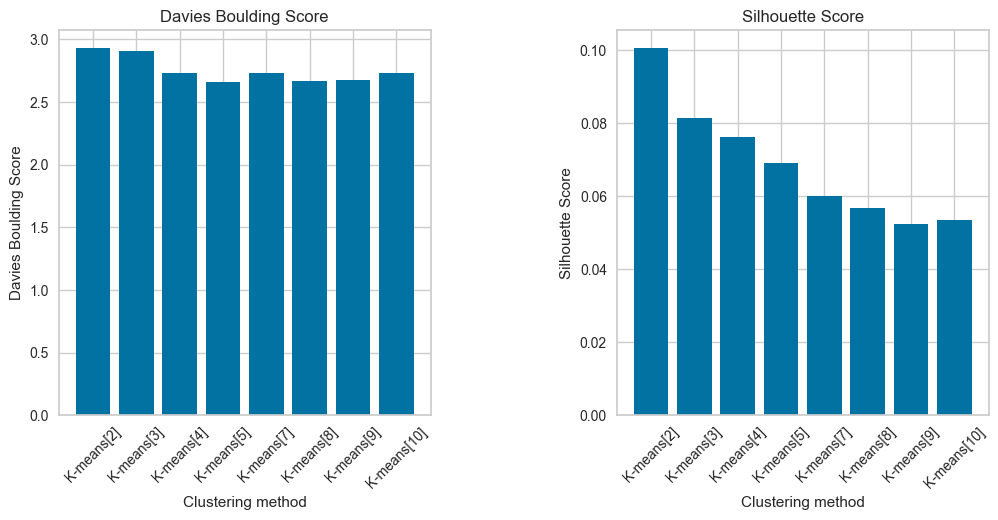

In [52]:
from sklearn.metrics import davies_bouldin_score, silhouette_score
kmean2 = clusterizar(2, df_scaled)
kmean3 = clusterizar(3, df_scaled)
kmean4 = clusterizar(4, df_scaled)
kmean5 = clusterizar(5, df_scaled)
kmean7 = clusterizar(7, df_scaled)
kmean8 = clusterizar(8, df_scaled)
kmean9 = clusterizar(9, df_scaled)
kmean10 = clusterizar(10, df_scaled)

clusters_to_compare = [kmean2, kmean3, kmean4, kmean5, kmean7, kmean8, kmean9, kmean10]
clustering_methods = ['K-means[2]', 'K-means[3]', 'K-means[4]', 'K-means[5]', 'K-means[7]', 'K-means[8]', 'K-means[9]', 'K-means[10]']

db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

for i in range(len(clusters_to_compare)):
    #calculamos metricas
    db_scores[i] = davies_bouldin_score(df_scaled, clusters_to_compare[i])
    silhouette_scores[i] = silhouette_score(df_scaled, clusters_to_compare[i])

    print(clustering_methods[i])
    print('DB score: {:,.4f}'.format(db_scores[i]))
    print('Silhouette score: {:.4f}'.format(silhouette_scores[i]))
    print('-------------')

# inicializamos un gráfico para cada métrica
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plt.subplots_adjust(wspace=0.5)

# graficamos el Davies Bouldin score
axes[0].bar(np.arange(db_scores.size), db_scores)
axes[0].set_title('Davies Boulding Score')
axes[0].set_xlabel('Clustering method')
axes[0].set_ylabel('Davies Boulding Score')
axes[0].set_xticks(np.arange(db_scores.size))
axes[0].set_xticklabels(clustering_methods, rotation=45)
axes[0].grid(True)

# y el Silhouette Score
axes[1].bar(np.arange(silhouette_scores.size), silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Clustering method')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(np.arange(silhouette_scores.size))
axes[1].set_xticklabels(clustering_methods, rotation=45)
axes[1].grid(True)

plt.show()

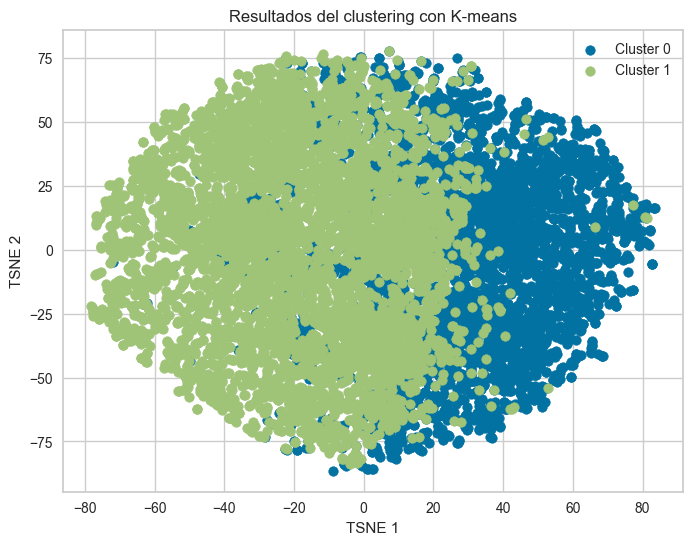

In [75]:
from cProfile import label
from sklearn.manifold import TSNE

t = 'tsne'
k = 2

if t == 'PCA':
    principalComponents = principalComponents_pca
elif t == 'tsne':
    principalComponents = principalComponents_tsne
else:
    principalComponents = principalComponents_umap

cluster_kmeans = clusterizar(k, df_scaled)

principalComponents_df = pd.DataFrame({'x': principalComponents[:, 0], 'y': principalComponents[:, 1], 'Cluster': cluster_kmeans})

plt.figure(figsize=(8, 6))
for cluster_num in range(k):
    plt.scatter(principalComponents_df[principalComponents_df['Cluster'] == cluster_num]['x'], principalComponents_df[principalComponents_df['Cluster'] == cluster_num]['y'], label=f'Cluster {cluster_num}')

plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.legend()
plt.title('Resultados del clustering con K-means')
plt.show()

In [54]:
for i in cols_numerics:
    if i != 'JobSat':
        out, _ = utils.get_ranges(df, i)
        df = df.drop(out.index)

In [76]:
X_num['Cluster'] = cluster_kmeans
X_num.groupby('Cluster')[cols_numerics].median()

,ResponseId,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,SO_Actions_1,SO_Actions_16,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
Cluster,,,,,,,,,,,,,,,,,
0,20206.0,20.0,26.0,7.0,4.0,5.0,3.0,6.0,5.0,4.0,5.0,5.0,4.0,8.0,10.0,110000.0,8.0
1,24901.0,7.0,10.0,5.0,4.0,4.0,2.0,5.0,4.0,5.0,6.0,6.0,5.0,7.0,10.0,54000.0,7.0


In [56]:
print("Número de clusters: ", len(set(cluster_kmeans)))

Número de clusters:  2


Number of clusters: 1


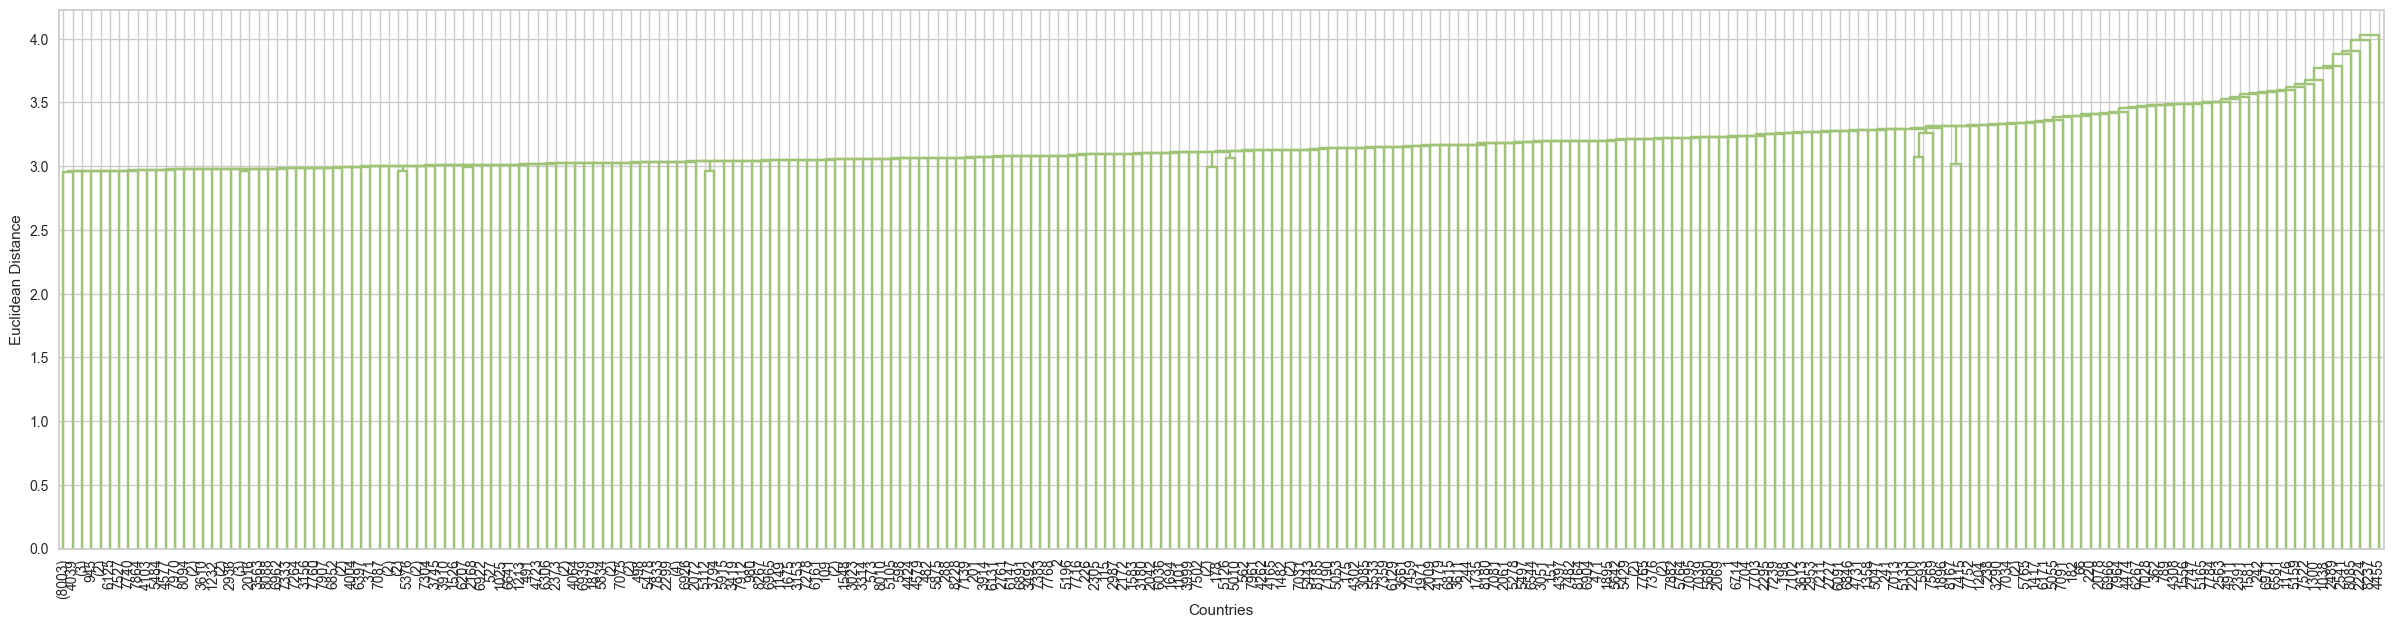

In [57]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

t=10

# generamos el clustering jerárquico
linked = linkage(df_scaled, metric="euclidean", method='single')

clusters = fcluster(linked, t=t, criterion='distance')
print(f"Number of clusters: {len(set(clusters))}")

# ploteamos el dendrograma
plt.figure(figsize=(30,7))
dendrogram(
    linked,
    truncate_mode='lastp',
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    p=250,
    leaf_font_size=10,
    above_threshold_color='blue',
    color_threshold=t
)
plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.axhline(y=t, color='red', linestyle='--')
plt.show()

In [58]:
X_num.loc[X_num.index, 'Cluster'] = clusters
X_num.groupby('Cluster')[cols_numerics].median()

,ResponseId,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,SO_Actions_1,SO_Actions_16,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
Cluster,,,,,,,,,,,,,,,,,
1,22255.0,10.0,15.0,6.0,4.0,4.0,2.0,6.0,4.0,5.0,5.0,6.0,4.0,8.0,10.0,72291.0,8.0


In [59]:
df.iloc[9718]['JobSat']

np.float64(5.0)

<h1 style="color: orange;">Limpieza de datos

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [168]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [376]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

,qname,question,type,sub
10,TechEndorse_13_TEXT,What attracts you to a technology or causes yo...,RO,Other (please specify): - Text
21,TechOppose_15_TEXT,What would turn you off or cause you to reject...,RO,Other (please specify): - Text
37,JobSatPoints_15_TEXT,Rank the following attributes of your current ...,RO,Other (please specify): - Text
48,SO_Actions_15_TEXT,"When visiting Stack Overflow, which following ...",RO,Other (write in): - Text
77,LanguagesHaveEntry,Was the programming language you use not liste...,TE,NaN
78,LanguagesWantEntry,Was the programming language you want to use n...,TE,NaN


Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

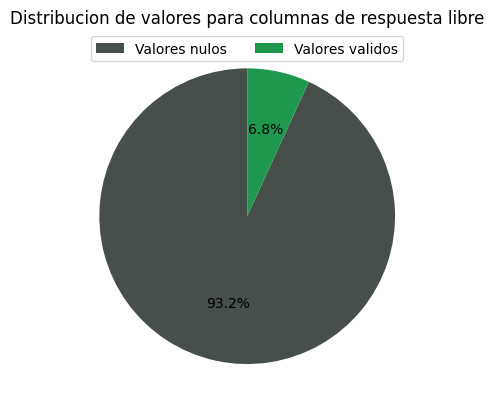

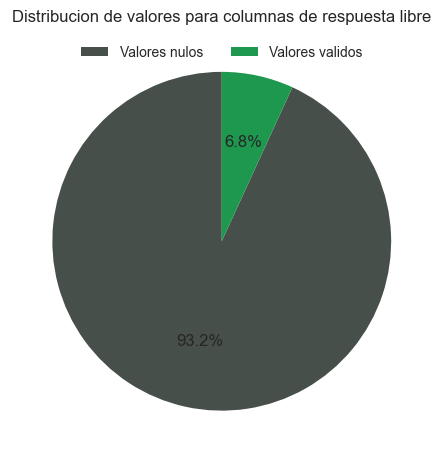

In [91]:
datos = df[var_free['qname'].tolist()]
frecuencias = [
    #Promedio de promedios de cada columna.
    datos.isna().mean().mean(),
    datos.notna().mean().mean()
]
utils.pie_chart(
    df,
    frecuencias,
    labels=['Valores nulos', 'Valores validos'],
    title='Distribucion de valores para columnas de respuesta libre',
    colors=["#474f4a", '#1e984f']
)

In [92]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

Promedio: 0.93152710861743 - Cantidad nulos: 1283037 - Cantidad no nulos: 94311 - Total: 1377348


In [377]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [378]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
var_SO[['qname', 'question']].head(3)

,qname,question
38,SO_Actions_1,"When visiting Stack Overflow, which following ..."
39,SO_Actions_16,"When visiting Stack Overflow, which following ..."
40,SO_Actions_3,"When visiting Stack Overflow, which following ..."


In [379]:
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas a la influencia de compra tecnologica

In [380]:
df = df.drop(columns=['PurchaseInfluence', 'TechEndorseIntro'])

<h3 style="color: violet;">Reduccion por redundancia o por alto porcentaje de valores nulos

<h4><u>Variables redundantes de moneda y remuneracion local

El Dataset nos aporta la moneda local y su remuneracion en ella para el encuestado en si, pero tambien nos ofrece la conversion a dolares. Por lo que, para trabajar con la misma unidad, nos quedamos con `ConvertedCompYearly`.

In [381]:
df = df.drop(columns=['CompTotal', 'Currency'])

<h4><u>Registros duplicados

In [382]:
df = df.drop_duplicates()

<h4><u>ID de registros

In [383]:
df = df.drop(columns='ResponseId')

<h4><u>Variables no numericas con un porcentaje de valores nulos altos

Realizamos un analisis para identificar la distribucion de valores nulos en estas variables. Por estandar aplicado por nuestra decision, decidimos eliminar todas aquellas que tienen mas de un 80% de valores nulos en su conjunto.

In [384]:
df.select_dtypes(exclude=['number']).isna().mean().mean()

np.float64(0.4975734545439031)

In [255]:
percentages = df.select_dtypes(exclude=['number']).isna().mean().sort_values(ascending=False)
drop_columns = percentages[percentages > 0.8].index.to_list()
df_80_nulls = pd.DataFrame({
    'Col': drop_columns
})
df_80_nulls

,Col
0,AIAgentObserveSecure
1,AIAgentKnowledge
2,AIAgentOrchestration
3,AIAgentImpactStrongly disagree
4,AIAgentImpactSomewhat disagree
5,AgentUsesGeneral
6,AIAgentImpactStrongly agree
7,AIAgentExternal
8,AIAgentChallengesStrongly disagree
9,AIAgentImpactNeutral


Podemos ver que se tratan de todas variables relacionadas al uso de Inteligencia artificial, por lo que primeramente comprobamos que dichos valores nulos no se correspondan por un valor especifico de la variable `AISelect` que justamente preguntaba el uso o no de dicha herramienta.

In [256]:
df.groupby('AISelect')[df.columns[df.columns.str.startswith('AI')]].apply(
    lambda x: x.isna().mean().mean() * 100
)

AISelect
No, and I don't plan to                        58.619146
No, but I plan to soon                         55.466627
Yes, I use AI tools daily                      39.209699
Yes, I use AI tools monthly or infrequently    48.381336
Yes, I use AI tools weekly                     42.988666
dtype: float64

En definitiva, podemos ver que usen o no el porcentaje de nulos se reparte en iguales. Por lo que decidimos definitivamente eliminar dichas columnmas con altos porcentajes de nulos

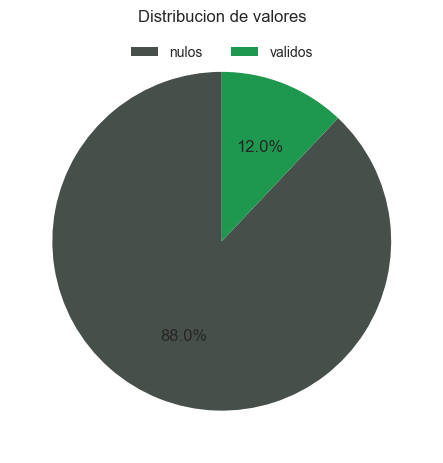

In [257]:
frecuencias = [df[drop_columns].isna().mean().mean(), df[drop_columns].notna().mean().mean()]
labels = ['nulos', 'validos']
utils.pie_chart(df, frecuencias, labels, colors=["#474f4a", '#1e984f'], title='Distribucion de valores')

In [385]:
df = df.drop(columns=drop_columns)

<h3 style="color: violet;">Normalizado de distribuciones de variables numericas

Mediante el analisis inicial decidimos observar un poco mas de cerca variables tales como `WorkExpr`, `YearsCode`, `JobSat`, `Age`, `ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly` ya que representaban distribuciones un poco extranas.

Recordamos que un valor outlier es aquel que se encuentra por debajo de Q1 - 1.5 x IQR o por encima de Q3 + 1.5 x IQR

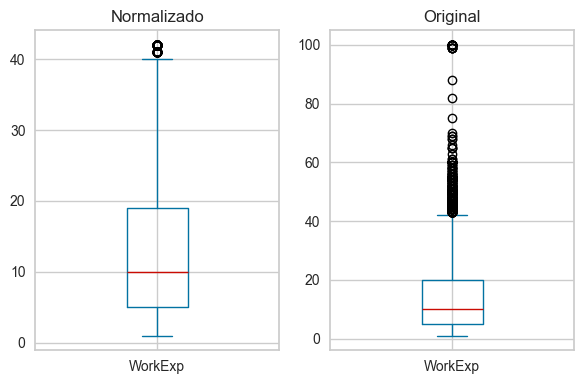

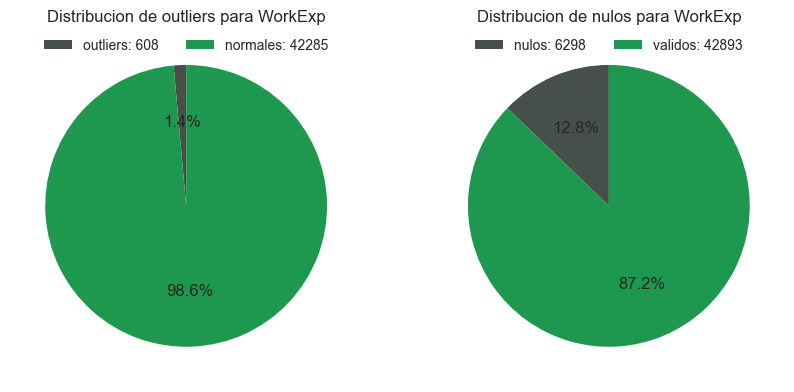

-------------------------------------------------------------------------------------------


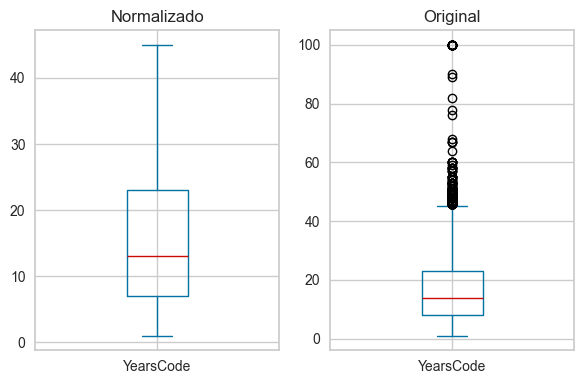

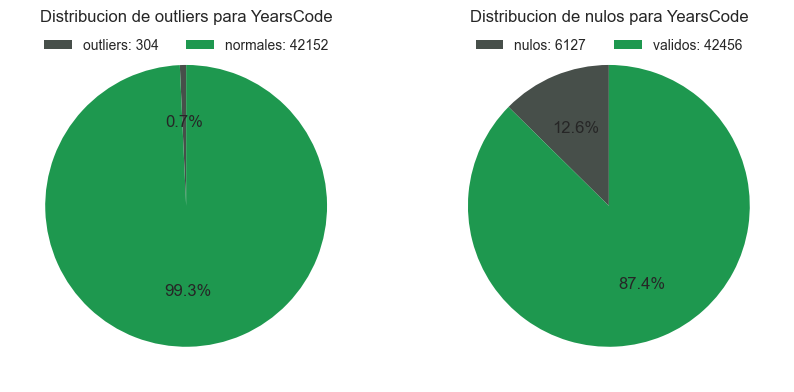

-------------------------------------------------------------------------------------------


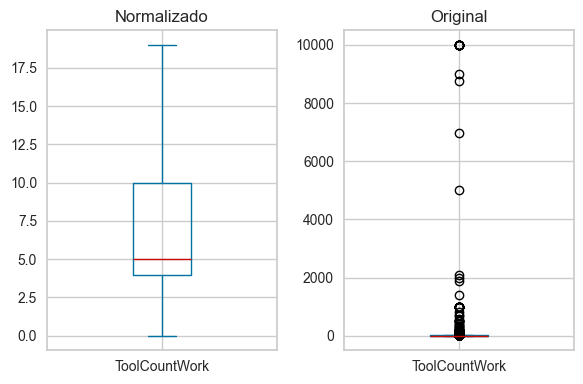

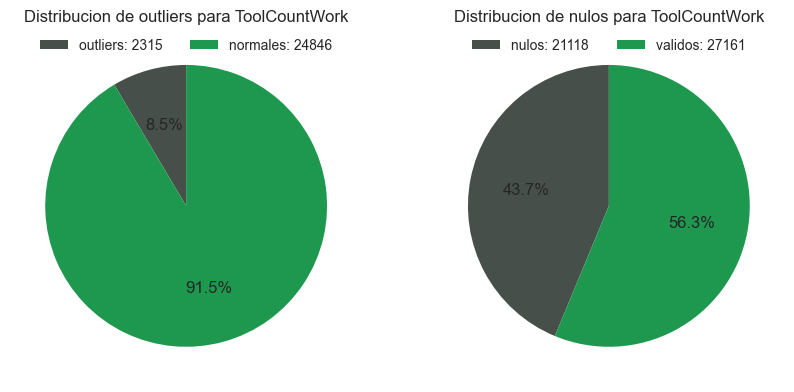

-------------------------------------------------------------------------------------------


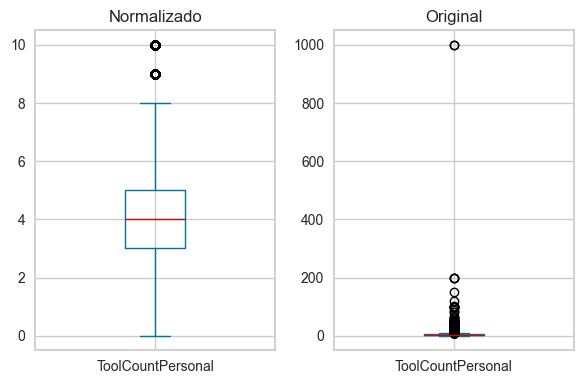

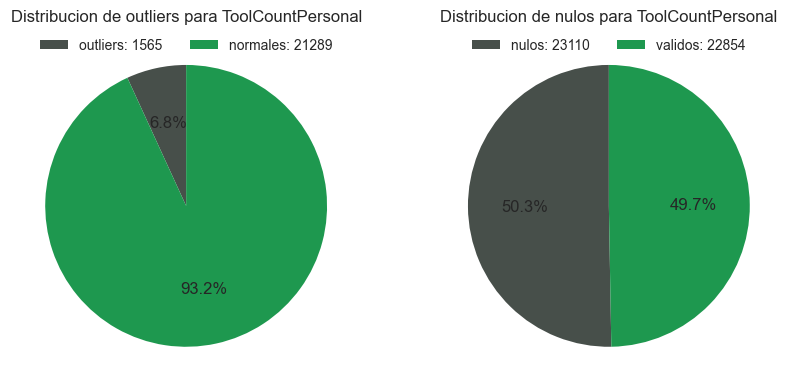

-------------------------------------------------------------------------------------------


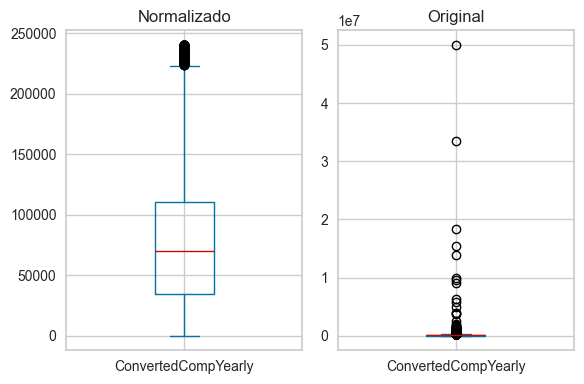

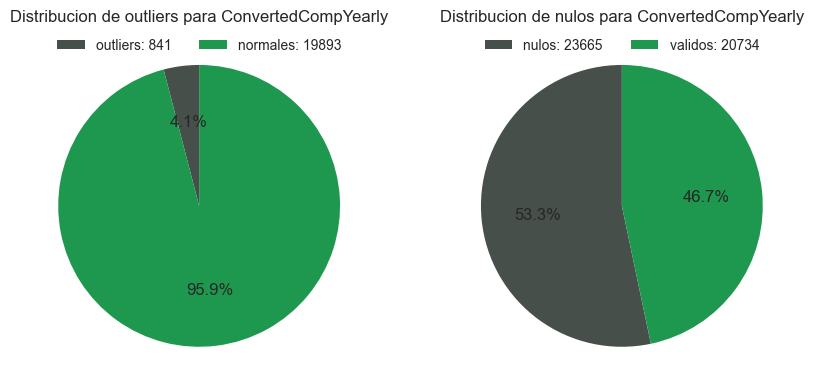

-------------------------------------------------------------------------------------------


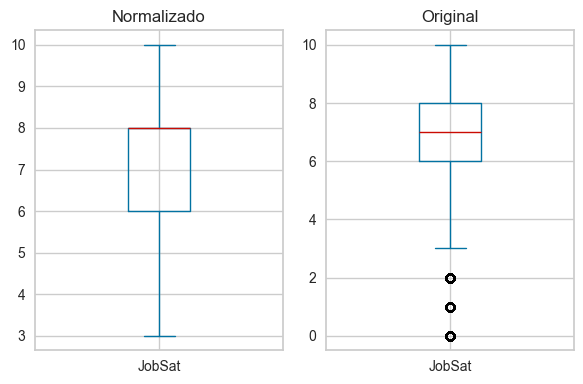

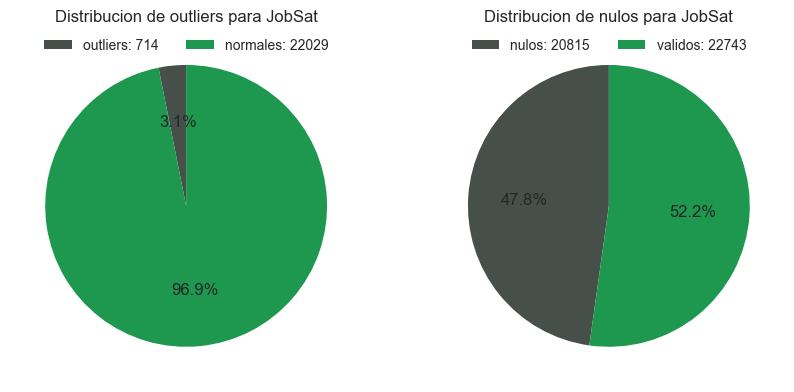

-------------------------------------------------------------------------------------------


In [386]:
cols = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'ConvertedCompYearly',
    'JobSat'
]
for i in cols:
    utils.box_plot_comparative(df, i)
    utils.graph_nulls_outliers(df, i)
    out, _ = utils.get_ranges(df, i)
    df = df.drop(out.index)
    print('-------------------------------------------------------------------------------------------')

El objetivo de esta limpieza fue la recuperacion de la distribucion mayoritaria de las variables, donde claramente en `WorkExpr`, `YearsCode`, `ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly` pudimos realizar dicha accion de forma muy efectiva.

<h1 style="color: orange;">Validacion de hipotesis

<h3 style="color: violet;">Univariada

ver si con el biplot graficando los que si tienen miedo de los que no, se va en direccion de la workexp

<h4><u>De aquellos desarrolladores que no tienen miedo a que la Inteligencia Artificial reemplace su trabajo, su experiencia laboral es superior a 5 años (se consideran seniors).

In [541]:
devs = df[df['AIThreat'] == 'No']

Vamos a usar un test de Student para una muestra planteando hipotesis a una cola. Es decir, planteamos que la hipotesis nula suponga que la media de anios de experencia laboral se encuentra por igual o debajo de 5 anios y que la hipotesis alternativa suponga lo contrario.

Por el teorma del limite central, podemos no comprobar la normalidad de la muestra gracias a que la media de la misma muestra tiende a una distribucion normal con un n > 30.

Planteamos
- H0: u <= 5
- H1: u > 5

In [553]:
import scipy.stats as stats

valor_referencia = 5

t_statistic, p_value = stats.ttest_1samp(
    devs['WorkExp'].dropna(),
    popmean=valor_referencia,
    alternative='greater'
)

print(f"Estadístico t: {t_statistic:.3f}")
print(f"p-valor: {p_value:.3f}")

Estadístico t: 106.194
p-valor: 0.000


Asi, dado p-valor < 0.05, rechazamos la hipotesis nula y aceptamos que la media de los anios de experencia es significativamente superior a 5 anios.

<h4><u>De los desarrolladores que no tienen miedo a que la Inteligencia Artificial reemplace su trabajo, la proporcion de aquellos que poseen al menos una carrera de grado es superior de los que no tienen.

In [555]:
df['EdLevel'].value_counts()

EdLevel
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                                          17718
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                                       10898
Some college/university study without earning a degree                                 5326
Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)     3262
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                                         2137
Associate degree (A.A., A.S., etc.)                                                    1348
Other (please specify):                                                                 599
Primary/elementary school                                                               528
Name: count, dtype: int64

In [574]:
devs = df[df['AIThreat'] == 'No']

In [575]:
mapped = {
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 1,
    'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)': 1,
    'Professional degree (JD, MD, Ph.D., Ed.D., etc.)': 1,

    'Some college/university study without earning a degree': 0,
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 0,
    'Associate degree (A.A., A.S., etc.)': 0,
    'Other (please specify):': 0,
    'Primary/elementary school': 0
}
    
devs['EdLevel'] = devs['EdLevel'].map(mapped)

C:\Users\Tomas\AppData\Local\Temp\ipykernel_6072\3846245685.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  devs['EdLevel'] = devs['EdLevel'].map(mapped)


In [582]:
from statsmodels.stats.proportion import proportions_ztest

#contamos los casos en los que los desarrolladores no tienen un título universitario
count = devs[devs['EdLevel'] == 1].shape[0]
n = len(devs)

value = 0.67
z_stat, p_value = proportions_ztest(count, n, value, alternative='larger')
print(f"Proporción real: {(count / n):.2%}")
print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-valor: {p_value:.4e}")

Proporción real: 68.24%
Estadístico Z: 3.6891
P-valor: 1.1254e-04


<h3 style="color: violet;">Bivariada

<h4><u>De aquellos desarrolladores senior que no confian de la IA, estos tienen mejor remuneracion que aquellos que si confian

Tenemos que nuestra variable que describe dicha confianza en la Inteligencia Artifical presenta valores tales como `Confiar hasta cierto punto`, `Desconfiar hasta cierto punto`, `Ni confiar ni desconfiar`, `Alta desconfianza` y `Alta confianza`. Decidimos, que para tener una relacion binaria de confianza o no confianza, mapear dichos valores a 0 o 1 segun corresponda el siguiente criterio:
- Highly distrust: 0
- Somewhat distrust: 0
- Neither trust nor distrust: np.nan
- Somewhat trust: 1
- Highly trust: 1

Por que mapeamos `ni confiar ni desconfiar a nan`? Porque consideramos que es un punto gris que no nos interesa para este analisis

In [423]:
df['AIAcc'].value_counts()

AIAcc
Somewhat trust                9869
Somewhat distrust             8685
Neither trust nor distrust    7162
Highly distrust               6533
Highly trust                  1048
Name: count, dtype: int64

In [479]:
data = df.copy()

In [480]:
data = data.dropna(subset=['ConvertedCompYearly'])

In [481]:
mapped = {
    'Highly distrust ': 0,
    'Somewhat distrust': 0,
    'Neither trust nor distrust': np.nan,
    'Somewhat trust': 1,
    'Highly trust': 1
}

data['AIAcc'] = df['AIAcc'].map(mapped)

Separamos dichos grupos anteriormente explicados

In [ ]:
devsSenior = data[data['WorkExp'] >= 10].dropna(subset=['ConvertedCompYearly'])
devsNotrust = devsSenior[devsSenior['AIAcc'] == 0]
devsTrust = devsSenior[devsSenior['AIAcc'] == 1]

In [498]:
import seaborn as sns
import matplotlib.pyplot as plt

Vamos a graficar y comparar las distribuciones en cuanto a la remuneracion total anual en dolares para cada grupo

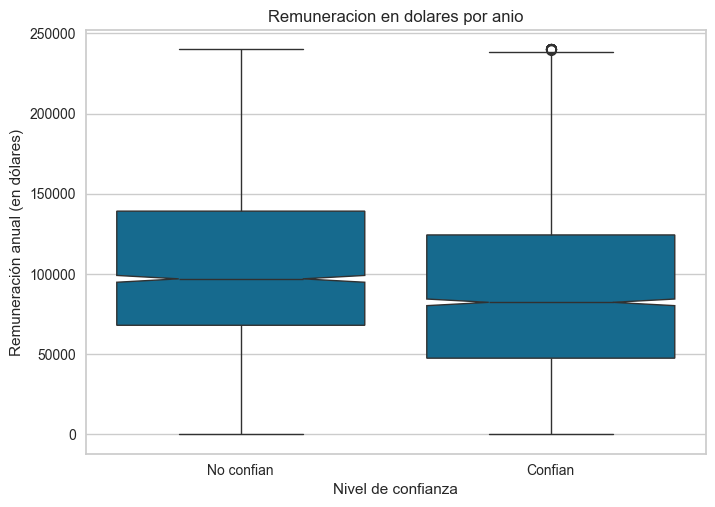

In [504]:
sns.boxplot(x='AIAcc', y='ConvertedCompYearly', data=devsSenior, notch=True)
plt.title("Remuneracion en dolares por anio")
plt.xlabel("Nivel de confianza")
plt.xticks(ticks=[0, 1], labels=["No confian", "Confian"])
plt.ylabel("Remuneración anual (en dólares)")
plt.show()

Pareciera existir diferencias significativas entre ambos grupos pero debemos probarlo estadisticamente. Para ver si podemos usar una prueba t-student para 2 medias verificamos si ambas muestran siguen una distribucion normal y ademas presentan homocedasticidad (igualdad de varianzas).

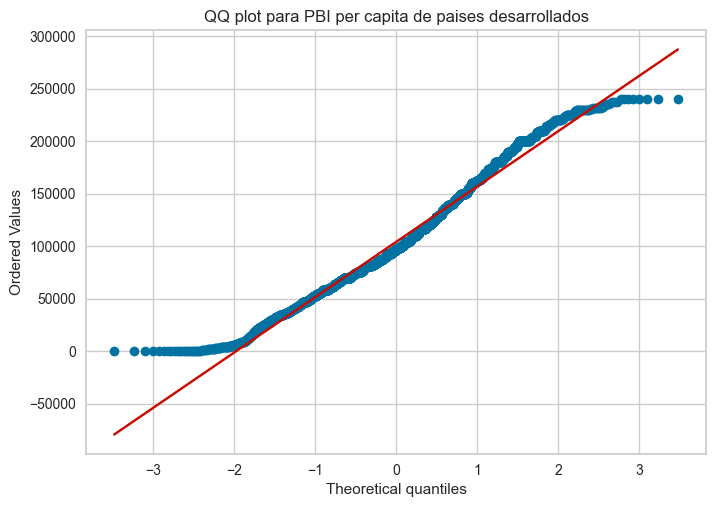

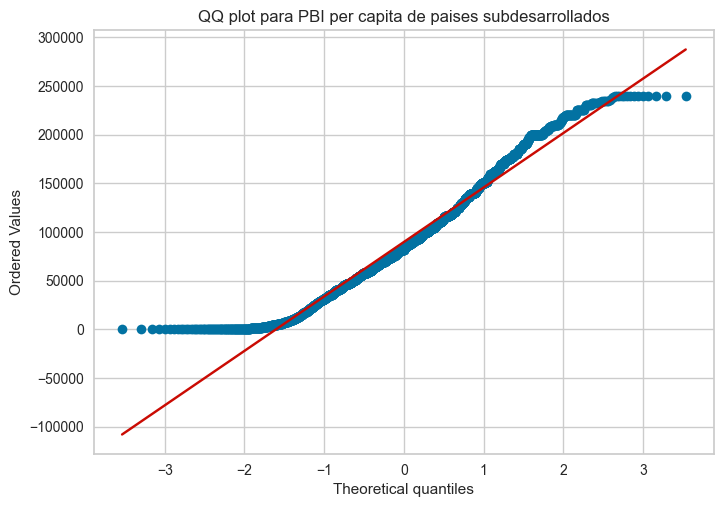

In [505]:
import scipy.stats as stats
#QQ plot para paises desarrollados
stats.probplot(devsNotrust['ConvertedCompYearly'], dist='norm', plot=plt)
plt.title('QQ plot para PBI per capita de paises desarrollados')
plt.show()

stats.probplot(devsTrust['ConvertedCompYearly'], dist='norm', plot=plt)
plt.title('QQ plot para PBI per capita de paises subdesarrollados')
plt.show()

A simple vista vemos que no siguen una distribucion normal, comprobamos mediante Shapiro-Wilks.

In [506]:
from scipy.stats import shapiro

stat, p = shapiro(devsNotrust['ConvertedCompYearly'])
print(f"Test de Shapiro-Wilk para países desarrollados: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para países desarrollados: Estadístico=0.980, p-valor=0.000


In [507]:
from scipy.stats import shapiro

stat, p = shapiro(devsTrust['ConvertedCompYearly'])
print(f"Test de Shapiro-Wilk para países desarrollados: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para países desarrollados: Estadístico=0.969, p-valor=0.000


Definitivamente ninguna muestra sigue una distribucion normal por lo que no podemos usar test t de student. Vamos a comprobar la homocedasticidad a ver si podemos usar el test de Mann-Whitney.

In [512]:
stat, p = stats.levene(devsNotrust['ConvertedCompYearly'], devsTrust['ConvertedCompYearly'])
print(f"Test de Levene para salarios: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para salarios: Estadístico=11.582, p-valor=0.001


Definitivamente tampoco tienen igualdad de varianzas, por lo que vamos a tener que usar el ultimo test no parametrico (Kruskal Wallis).

In [513]:
stat, p = stats.kruskal(devsNotrust['ConvertedCompYearly'], devsTrust['ConvertedCompYearly'])
print(f"Test de Kruskal-Wallis para salarios: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.")

Test de Kruskal-Wallis para salarios: Estadístico=112.840, p-valor=0.000
Se rechaza la hipótesis nula.
Existe diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.


Finalmente pudimos comprobar estadisticamente que ambas muestran presentan diferencias significativas en la remuneracion total anual en dolares. Como vimos antes en el box-plot, aquellos desarrolladores que no confian de la Inteligencia Artifial poseen dicha remuneracion superior al grupo que si confia.

Que nos puede llegar a decir dicho test? Que tal vez aquellos desarrolladores senior con una critica superior a dichas herramientas puedan tomar decisiones de auditacion que eviten errores o alucinaciones y mejoren su reconocimiento laboral para reflejarse en una mejor remuneracion.

---------------------------------------------------------------------------------------------------------------------------------------------------------------

In [235]:
data = df.copy()

---------------------------------------------------------------------------------------------------------------------------------------------------------------

In [350]:
df['AIFrustration'].notna().sum()

np.int64(31522)

In [349]:
df[df['AIFrustration'].str.startswith(
    'Other (write in):',
    na=False
)]['AIFrustration'].value_counts()

AIFrustration
Other (write in):                                                      720
Other (write in):;It’s hard to understand how or why the code works     21
Other (write in):;I haven’t encountered any problems                    18
Name: count, dtype: int64

In [196]:
data = df.copy()

In [197]:
mapa_confianza = {
    'Very poor at handling complex tasks': 1,
    'Bad at handling complex tasks': 2,
    'Neither good or bad at handling complex tasks': 3,
    'Good, but not great at handling complex tasks': 4,
    'Very well at handling complex tasks': 5,
    "I don't use AI tools for complex tasks / I don't know": np.nan
}

data['AIComplex'] = df['AIComplex'].map(mapa_confianza)

In [198]:
mapa_confianza = {
    'Highly distrust': 1,
    'Somewhat distrust': 2,
    'Neither trust nor distrust': 3,
    'Somewhat trust': 4,
    'Highly trust': 5,
}

data['AIAcc'] = df['AIAcc'].map(mapa_confianza)

In [ ]:
df['NewRole'].value_counts()

In [199]:

mapa_confianza = {
    'I have neither consider or transitioned into a new career or industry': 0,
    'I have somewhat considered changing my career and/or the industry I work in': 1,
    'I have strongly considered changing my career and/or the industry I work in': 1,
    'I have transitioned into a new career and/or industry voluntarily': 1,
    'I have transitioned into a new career and/or industry involuntarily': np.nan
}

data['NewRole'] = df['NewRole'].map(mapa_confianza)

In [334]:
cantidad = df['AIFrustration'].str.startswith('Other (write in):', na=False).sum()
cantidad

np.int64(759)

In [200]:
# Transformación y limpieza: AIFrustration ✅

import numpy as np
import pandas as pd

# 1. Definimos el diccionario mapeando cada opción a su puntaje
mapeo_frustracion = {
    'AI solutions that are almost right, but not quite': 1,
    'Debugging AI-generated code is more time-consuming': 1,
    "I've become less confident in my own problem-solving": 1,
    "It's hard to understand how or why the code works": 1,
    "I haven't encountered any problems": 0,
    "I don't use AI tools regularly": 0
}                                                

# 2. Función para mapear y sumar cuando hay múltiples respuestas en una celda
def mapear_opciones_multiples(celda):
    if pd.isna(celda):
        return np.nan
    
    # Estandarizamos comillas (convierte comilla curvada ’ en estándar ')
    celda_normalizada = str(celda).replace('’', "'")
    
    # Separamos la celda por punto y coma
    opciones_seleccionadas = celda_normalizada.split(';')
    
    # Las entradas de "(write in)" generan datos ruidosos y dificiles de estandarizar por lo que buscamos cada opción en el diccionario (si no existe o es "Other", devuelve 0).
    score = sum(mapeo_frustracion.get(opcion.strip(), 0) for opcion in opciones_seleccionadas)
    
    return score

# 3. Aplicamos la transformación
data['AIFrustration_score'] = df['AIFrustration'].apply(mapear_opciones_multiples)

# 4. Verificamos los resultados
print(data['AIFrustration_score'].value_counts(dropna=False).sort_index())

# JobSat tiene ≈ 6.84% de nulos cuando se hace el tratamiento de las 4 variables anteriores. Decido eliminar esas filas ya que conservo más de 17500 registros, que sigue siendo un buen número a analizar.
data = data.dropna(subset=['AIFrustration_score'])

AIFrustration_score
0.0     4367
1.0     9454
2.0     8092
3.0     3136
4.0      815
NaN    16980
Name: count, dtype: int64


In [77]:
import numpy as np
import statsmodels.api as sm

In [201]:
data = data.dropna(subset=['AIAcc','ConvertedCompYearly', 'WorkExp', 'JobSat', 'AIThreat', 'AIComplex', 'AIFrustration_score'])

In [202]:
data

,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,...,AIAgent_Uses,AIAgentImpactSomewhat agree,AIAgentChallengesNeutral,AIAgentChallengesSomewhat disagree,AIAgentChallengesStrongly agree,AIAgentChallengesSomewhat agree,AIHuman,ConvertedCompYearly,JobSat,AIFrustration_score
0,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,...,Software engineering,AI agents have increased my productivity.;AI a...,I am concerned about the accuracy of the infor...,Integrating AI agents with my existing tools a...,The cost of using certain AI agent platforms i...,NaN,When I don’t trust AI’s answers,61256.0,10.0,1.0
1,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,...,NaN,NaN,It takes significant time and effort to learn ...,NaN,I am concerned about the accuracy of the infor...,Integrating AI agents with my existing tools a...,When I don’t trust AI’s answers;When I want to...,104413.0,9.0,2.0
2,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Technical ...,...,Software engineering,AI agents have increased my productivity.;AI a...,It takes significant time and effort to learn ...,My company's IT and/or InfoSec teams have stri...,NaN,I am concerned about the accuracy of the infor...,When I don’t trust AI’s answers;When I want to...,53061.0,8.0,2.0
3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Videos (no...,...,Software engineering,AI agents have accelerated my learning about n...,It takes significant time and effort to learn ...,NaN,I am concerned about the accuracy of the infor...,Integrating AI agents with my existing tools a...,When I don’t trust AI’s answers;When I want to...,36197.0,6.0,1.0
4,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",Technical documentation (is generated for/by t...,...,NaN,NaN,Integrating AI agents with my existing tools a...,NaN,I am concerned about the accuracy of the infor...,It takes significant time and effort to learn ...,When I don’t trust AI’s answers,60000.0,7.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49026,I am a developer by profession,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Stack Overflow or Stack Exchange;Technical doc...,"Yes, I learned how to use AI-enabled tools req...",AI CodeGen tools or AI-enabled apps,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69609.0,8.0,1.0
49048,I am a developer by profession,45-54 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Engaged in paid work (20-29 hours per week),23.0,"No, I am not new

In [205]:
estandar = 'estandar' # Cambiar a 'minmax' para usar MinMaxScaler
if estandar == 'estandar':
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
else:
    from sklearn.preprocessing import MinMaxScaler
    scaler = MinMaxScaler()

features_scaled = scaler.fit_transform(data[['AIAcc','ConvertedCompYearly', 'WorkExp', 'JobSat', 'AIComplex', 'AIFrustration_score']])

In [207]:
data_scaled = pd.DataFrame(features_scaled, columns=['AIAcc','ConvertedCompYearly', 'WorkExp', 'JobSat', 'AIComplex', 'AIFrustration_score'])

In [106]:
len(data['NewRole'])

12188

In [107]:
len(data_scaled)

12188

In [300]:
data['AIAcc'].value_counts()

AIAcc
4.0    5182
2.0    4044
3.0    3501
1.0    2416
5.0     421
Name: count, dtype: int64

In [214]:
principalComponents_umap = umap.fit_transform(data_scaled)

In [184]:
principalComponents_pca = pca.fit_transform(data_scaled)

In [263]:

principalComponents_df = principalComponents_pca

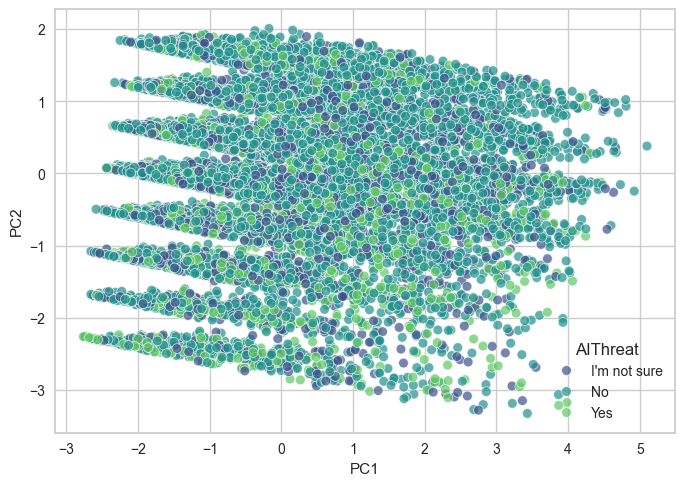

In [264]:
import seaborn as sns

pca_plot = pd.DataFrame({
    'PC1': principalComponents_df[:, 0],
    'PC2': principalComponents_df[:, 1],
    'AIThreat': X_num['AIThreat'].values
})

sns.scatterplot(
    data=pca_plot,
    x='PC1',
    y='PC2',
    hue='AIThreat',
    alpha=0.7,
    palette='viridis'
)

plt.grid(True)
plt.show()

ValueError: 'c' argument must be a color, a sequence of colors, or a sequence of numbers, not 0        I'm not sure
1        I'm not sure
2                  No
3                  No
4                  No
             ...     
49185             NaN
49186             NaN
49187             NaN
49189             NaN
49190             NaN
Name: AIThreat, Length: 42844, dtype: object

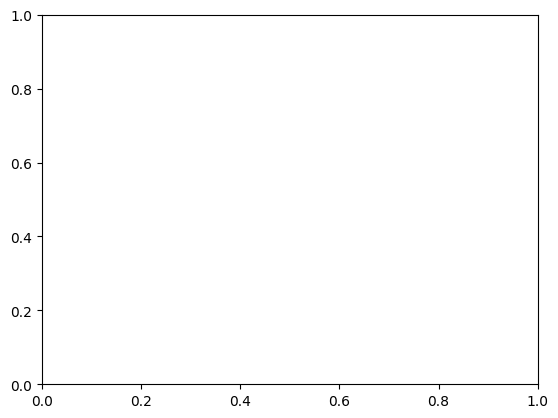

In [210]:
plt.scatter(principalComponents_df[:,0], principalComponents_df[:,1], c=df['AIThreat'], cmap='viridis', alpha=0.7)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar()
plt.show()

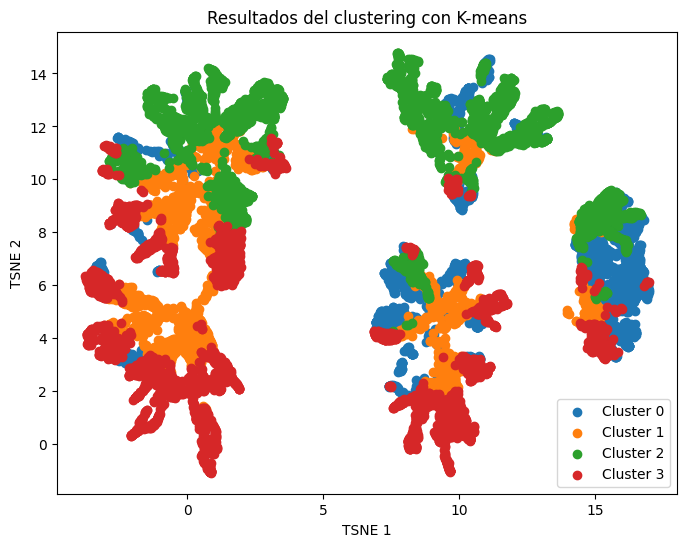

In [134]:
from cProfile import label
from sklearn.manifold import TSNE

t = 'umap'
k = 4

if t == 'PCA':
    principalComponents = principalComponents_pca
elif t == 'tsne':
    principalComponents = principalComponents_tsne
else:
    principalComponents = principalComponents_umap

cluster_kmeans = clusterizar(k, data_scaled)

principalComponents_df = pd.DataFrame({'x': principalComponents[:, 0], 'y': principalComponents[:, 1], 'Cluster': cluster_kmeans})

plt.figure(figsize=(8, 6))
for cluster_num in range(k):
    plt.scatter(principalComponents_df[principalComponents_df['Cluster'] == cluster_num]['x'], principalComponents_df[principalComponents_df['Cluster'] == cluster_num]['y'], label=f'Cluster {cluster_num}')

plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.legend()
plt.title('Resultados del clustering con K-means')
plt.show()

In [69]:
cols = [
    'WorkExp',
    'ConvertedCompYearly',
    'JobSat',
    'AIComplex',
    'AIAcc',
    'AIFrustration_score'
]
data['Cluster'] = cluster_kmeans
data.groupby('Cluster')[cols].median()

,WorkExp,ConvertedCompYearly,JobSat,AIComplex,AIAcc,AIFrustration_score
Cluster,,,,,,
0,10.0,61879.5,8.0,4.0,4.0,1.0
1,10.0,82370.0,7.0,2.0,2.0,2.0


In [118]:
X, y = X.align(y, join='inner', axis=0)

In [110]:
print(X.index.equals(y.index))
print(X.index)
print(y.index)

False
RangeIndex(start=0, stop=12188, step=1)
Index([    0,     1,     3,     4,     5,     6,     7,     9,    10,    12,
       ...
       49006, 49008, 49010, 49014, 49017, 49026, 49048, 49056, 49066, 49121],
      dtype='int64', length=12188)


In [112]:
model = sm.OLS(y, X).fit()

In [119]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0. ,-0.02, 0. ,..., 0.01,-0.01,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['const','ConvertedCompYearly','WorkExp',...,'AIComplex','AIAcc', 'AIFrustration_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.527
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,6


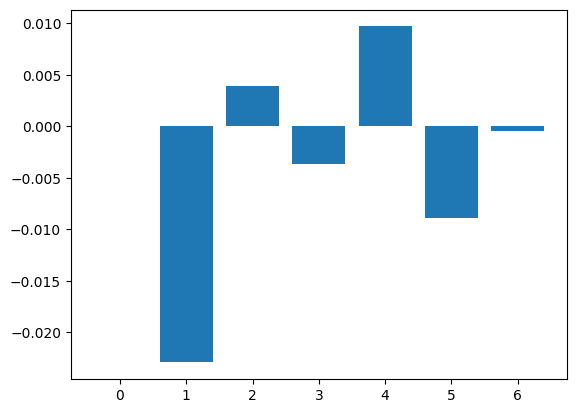

In [120]:
theta = model.coef_

# y los mostramos por pantalla
fig = plt.figure()
ax = fig.gca()
ax.bar(np.arange(0,theta.size), np.squeeze(theta))
ax.set_xticks(np.arange(0,theta.size))
plt.show()

In [113]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                NewRole   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.392
Date:                Sat, 07 Nov 2026   Prob (F-statistic):              0.214
Time:                        15:59:10   Log-Likelihood:                -2662.4
No. Observations:                3681   AIC:                             5339.
Df Residuals:                    3674   BIC:                             5382.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.5270    

In [234]:
# Seleccionamos variables numéricas
df_num = df.select_dtypes(include=[np.number])

# Calculamos correlación de cada variable con JobSat
correlaciones = df_num.corr()['JobSat'].drop('JobSat')  # Eliminamos la correlación de JobSat consigo misma

# Convertimos a DataFrame y ordenamos
df_correlaciones = correlaciones.to_frame(name='Correlación con JobSat')
df_correlaciones = df_correlaciones.sort_values(
    by='Correlación con JobSat',
    ascending=False
)

df_correlaciones

,Correlación con JobSat
WorkExp,0.108277
ConvertedCompYearly,0.102227
YearsCode,0.096413
JobSatPoints_11,0.062885
JobSatPoints_4,0.050600
TechOppose_2,0.028424
JobSatPoints_8,0.028212
TechEndorse_2,0.026426
TechOppose_11,0.022294
JobSatPoints_13,0.019066
